<a href="https://colab.research.google.com/github/emlluc/Data201-lab/blob/main/Homework8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 Homework

Packages/Preparing Data:

In [1]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score



In [3]:
hitters = load_data('Hitters')
# Remove the missing information
hitters = hitters.dropna(subset=['Salary']).copy()

# Set your features and target
X = hitters.drop(columns='Salary')
y = hitters['Salary']    # thousands of dollars

# Define num/cat for later scaling and encoding
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
category_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print(category_cols)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

['League', 'Division', 'NewLeague']


Lasso Models with 3 Alphas:

In [4]:
# Pre-model prep
def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), category_cols)
            ])

baseline = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', LinearRegression())
])

baseline.fit(X_train, y_train)

def measure(name, fitted_model):
    train_pred = fitted_model.predict(X_train)
    test_pred = fitted_model.predict(X_test)
    return {
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    }

results = [measure('Linear regression (no penalty)', baseline)]
display(pd.DataFrame(results).round(2))

,Model,Train RMSE,Test RMSE,Test R²
0,Linear regression (no penalty),289.33,357.05,0.41


In [5]:
# Ftting 3 models
alpha_values = [0.1, 10, 100]
rows = []

for a in alpha_values:
    pipe = Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', Lasso(alpha=a, max_iter=30000))
    ])
    pipe.fit(X_train, y_train)

    # get the model's coefficients
    coefs = pipe.named_steps['model'].coef_

    # predictions for train and test sets
    train_preds = pipe.predict(X_train)
    test_preds = pipe.predict(X_test)

    rows.append({
        'alpha': a,
        'Nonzero coefficients': int(np.sum(np.abs(coefs) > 1e-6)),
        'Training RMSE': np.sqrt(mean_squared_error(y_train, train_preds)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_preds))
    })

alpha_table = pd.DataFrame(rows)
display(alpha_table.round(2))

,alpha,Nonzero coefficients,Training RMSE,Test RMSE
0,0.1,19,289.38,356.83
1,10.0,9,303.10,381.84
2,100.0,5,341.39,395.12


**Questions**
1. As α increases, what happens to the number of retained predictors?
As alpha increases, the number of retained predictors goes down.
2. Does a smaller number of predictors always lead to a lower test RMSE?
No, because in the table above, the training RMSE climbs when the number of predictors drops.

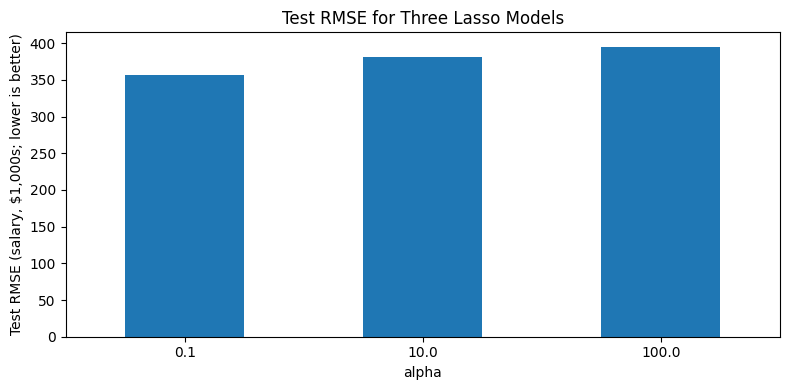

In [14]:
# Bar graph, side by side: α versus Test RMSE for the three models:
ax = alpha_table.plot(kind='bar', x='alpha', y='Test RMSE', legend=False, figsize=(8, 4))
ax.set_ylabel('Test RMSE (salary, $1,000s; lower is better)')
ax.set_title('Test RMSE for Three Lasso Models')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Questions**
1. Which α produces the lowest test RMSE among the three values?
alpha=0.1 produced the lowest test RMSE (356.83)

2. Which α appears to cause the most underfitting? Explain using bias.
alpha=100 causes the most underfitting. The model is too simple, only retaining 5/19 predictors. Therefore, the bias is too high (the model is too picky about how it sorts the data).

3. Why might a model with higher training RMSE produce lower test RMSE?
Regularization models generate more error on the training set to achieve a better testing set. While this is an element of overfitting, regularization methods like lasso are used to "reign the model in".

Model Interpretation:
1. Identify two predictors that Lasso sets to zero at α = 100.
Predictors: num__CHits and num__Years
2. Does setting their coefficients to zero prove that these predictors have no relationship with salary? Explain.
No, because the lasso algorithim will set a coefficient to zero because it is correlated with other predictors, not it's relationship with the target variable.
3. If two models have very similar test RMSE but one uses fewer predictors, which wouldyou prefer? Explain your answer in terms of interpretability and predictive performance.
Although you can choose either to prevent over/under fitting, I would choose the model with fewer predictors because it uses the least amount of memory.

Regression Model Scenarios:

- Scenario A: A researcher has data from 80 patients with 200 medical measurements. The goal is to identify a small number of measurements that may be useful for predicting disease severity.

Lasso linear regression is the best choice because the number of measurements that is being found is small. Lasso will minimize the 200 medical measurements to get closer to the goal.

- Scenario B: A company wants to predict employee salaries using 40 predictors. Many predictors are strongly correlated, and the company believes most contain useful information. Keeping all predictors is not a concern.

Ridge linear regression is the best choice because the predictors are already important and correlated. Compared to lasso, ridge will keep all predictors, insuring that no integral data is lost.

- Scenario C: A researcher has 10,000 observations and only three predictors. The relationship appears approximately linear, and the researcher wants a simple model that is easy to interpret.

Ordinary linear regression is the best choice because it is the most simple. For more fine tuning, ridge would be more likely needed over lasso because there are only 3 predictors. However, this would only be in the case of overfitting.

- Scenario D: A company has 500 observations and 25 predictors. It is unclear how many predictors are useful or how strongly they are correlated. The company wants the most accurate predictions possible

Cross-validation must be used here. Lasso could cut out important predictors (found through cv), and olr could be innacurate if the predictors are strongly correlated (also found through cv). Given this, ridge would be the safest option out of the three (but not necessarily the most accurate!).